# Phase 2 — Chronic Stockout Risk: Five-Model Evaluation (55C-V2)

**Project:** Machine Learning for Chronic Stockout Risk Assessment: Implications for Quick-Commerce Inventory Planning  
**Team:** Nishant Khandelwal, Anwesha Banerjee, Anisha Saha

This notebook implements the **five models promised in the first-review IEEE manuscript** (Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost) on two strictly defined input groups (**core** and **policy-augmented**). It uses the original, unscaled inventory CSV and a common **70% / 15% / 15% stratified split**. Imputation, encoding and any scaling are fitted on training records only. Model selection uses **validation average precision**; test records are not used to choose the model.

**Interpretation:** The dataset is simulated and summarizes inventory scenarios, so outputs classify the *supplied chronic-stockout label*, not future stockouts. No causal policy benefits or live monetary savings are inferred.

**Upload before running:** `inventory_optimization.csv` to Colab's Files pane (default directory `/content/`). Do not use an earlier `cleaned_inventory_optimization.csv` that has been standardized or contains invalid engineered columns.


## 1. Install missing classifiers (Colab/Jupyter)

In [5]:
%pip -q install xgboost lightgbm catboost

## 2. Load source file; validate label and input schema

In [6]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, lightgbm, catboost

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             brier_score_loss, PrecisionRecallDisplay, ConfusionMatrixDisplay,
                             precision_recall_curve)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 42
DATA_PATH = Path('inventory_optimization.csv')
assert DATA_PATH.is_file(), "Upload original 'inventory_optimization.csv' into Colab Files (not the cleaned CSV)."
df = pd.read_csv(DATA_PATH)
CORE_FEATURES = [
    'category', 'ignores_lead_time_variability', 'mean_daily_demand',
    'sigma_daily_demand', 'demand_cv', 'mean_lead_time',
    'sigma_lead_time', 'lead_time_cv', 'unit_cost',
    'holding_rate_annual', 'stockout_penalty', 'order_cost'
]
POLICY_FEATURES = ['target_service_level', 'safety_stock', 'reorder_point', 'order_quantity']
FEATURE_SETS = {'Core': CORE_FEATURES,
                'Policy-augmented': CORE_FEATURES + POLICY_FEATURES}
TARGET = 'stockout_occurred'
required = set(FEATURE_SETS['Policy-augmented'] + [TARGET, 'stockout_frequency'])
missing_cols = sorted(required - set(df.columns))
assert not missing_cols, f'Missing source columns: {missing_cols}'
assert df[TARGET].notna().all() and df['stockout_frequency'].notna().all(), 'Missing target values detected'
assert df[TARGET].isin([0, 1]).all(), 'Target must contain only 0 or 1'
assert df['stockout_frequency'].between(0,1).all(), 'Unexpected stockout-frequency values'
assert ((df['stockout_frequency'] >= 0.20).astype(int) == df[TARGET]).all(), 'Target disagrees with documented frequency rule'
assert not df[FEATURE_SETS['Policy-augmented']].isna().all(axis=0).any(), 'One feature is entirely missing'
assert df.shape[0] == 45000, f'Unexpected record count: {df.shape[0]}'
assert df['sku_id'].is_unique, 'SKU IDs are not unique; investigate overlapping entities'

print('Original shape:', df.shape)
print('Target distribution:', df[TARGET].value_counts().sort_index().to_dict())
print('Core variables:', len(CORE_FEATURES), '| Policy-augmented variables:', len(FEATURE_SETS['Policy-augmented']))
print('Excluded: all other columns, including sku_id, realized outcomes, costs and stockout_frequency.')


Original shape: (45000, 28)
Target distribution: {0: 31202, 1: 13798}
Core variables: 12 | Policy-augmented variables: 16
Excluded: all other columns, including sku_id, realized outcomes, costs and stockout_frequency.


## 3. Split once, keeping identical records across all 10 experiments

In [7]:
indices = np.arange(len(df))
trainval_idx, test_idx = train_test_split(indices, test_size=0.15, stratify=df[TARGET], random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx,
    test_size=0.15 / 0.85, stratify=df.loc[trainval_idx, TARGET], random_state=SEED)
y = df[TARGET]
y_train, y_val, y_test = y.iloc[train_idx], y.iloc[val_idx], y.iloc[test_idx]
print('Train / validation / test:', len(train_idx), len(val_idx), len(test_idx))
print('Target prevalence:', {k: round(float(v.mean()), 4)
      for k, v in [('train', y_train), ('validation', y_val), ('test', y_test)]})
assert (len(train_idx), len(val_idx), len(test_idx)) == (31500, 6750, 6750)
assert not (set(train_idx)&set(val_idx) or set(val_idx)&set(test_idx) or set(train_idx)&set(test_idx))


Train / validation / test: 31500 6750 6750
Target prevalence: {'train': 0.3066, 'validation': 0.3067, 'test': 0.3067}


## 4. Training-only preprocessing, classifiers, and reproducible metric functions

In [8]:
def build_preprocessor(features, scale_numeric=False):
    cat_cols = [col for col in features if df[col].dtype == 'object' or str(df[col].dtype) == 'category']
    num_cols = [col for col in features if col not in cat_cols]
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), num_cols),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ], remainder='drop', sparse_threshold=0)

def get_models():
    return {
        'Logistic Regression': LogisticRegression(max_iter=1500, random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=180, max_depth=10,
                            min_samples_leaf=5, random_state=SEED, n_jobs=2),
        'XGBoost': XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.06,
                         subsample=0.9, colsample_bytree=0.9, random_state=SEED,
                         tree_method='hist', eval_metric='logloss', n_jobs=2),
        'LightGBM': LGBMClassifier(n_estimators=250, num_leaves=23, learning_rate=0.06,
                         min_child_samples=30, random_state=SEED, n_jobs=2, verbosity=-1),
        'CatBoost': CatBoostClassifier(iterations=250, depth=5, learning_rate=0.07,
                         loss_function='Logloss', random_seed=SEED,
                         verbose=False, thread_count=2, allow_writing_files=False)
    }

def predict_positive(pipe, X):
    # Bypass sklearn Pipeline.predict_proba fitted-tag checks (CatBoost compatibility with newer sklearn).
    # The fitted training-only transformer is still applied before model inference.
    return pipe.named_steps['classifier'].predict_proba(pipe.named_steps['preprocess'].transform(X))[:,1]

def evaluate(probs, labels, threshold=0.50):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0,1]).ravel()
    return {'precision': precision_score(labels, pred, zero_division=0),
            'recall': recall_score(labels, pred, zero_division=0),
            'f1': f1_score(labels, pred, zero_division=0),
            'accuracy': accuracy_score(labels, pred),
            'roc_auc': roc_auc_score(labels, probs),
            'average_precision': average_precision_score(labels, probs),
            'brier_score': brier_score_loss(labels, probs),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

OUT = Path('outputs'); FIG = OUT / 'figures'; TAB = OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)


## 5. Fit the 5 models on each feature set; evaluate validation only for model selection

In [9]:
fitted = {}
validation_rows = []
for feature_group, features in FEATURE_SETS.items():
    for model_name, estimator in get_models().items():
        pipe = Pipeline([
            ('preprocess', build_preprocessor(features, scale_numeric=(model_name == 'Logistic Regression'))),
            ('classifier', estimator)
        ])
        pipe.fit(df.iloc[train_idx][features], y_train)
        val_proba = predict_positive(pipe, df.iloc[val_idx][features])
        result = {'feature_set': feature_group, 'model': model_name,
                  **evaluate(val_proba, y_val)}
        fitted[(feature_group, model_name)] = pipe
        validation_rows.append(result)
        print(f'{feature_group:18} | {model_name:22} | Val AP={result["average_precision"]:.4f} | F1={result["f1"]:.4f}')
validation_results = pd.DataFrame(validation_rows).sort_values(['feature_set','average_precision'], ascending=[True,False])
validation_results.to_csv(TAB/'validation_metrics.csv', index=False)
print('\nValidation results (used for model selection):')
display(validation_results[['feature_set','model','precision','recall','f1','average_precision','roc_auc','brier_score']].round(4))


Core               | Logistic Regression    | Val AP=0.7034 | F1=0.6142
Core               | Random Forest          | Val AP=0.7150 | F1=0.6220
Core               | XGBoost                | Val AP=0.7147 | F1=0.6284


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Core               | LightGBM               | Val AP=0.7071 | F1=0.6281
Core               | CatBoost               | Val AP=0.7154 | F1=0.6290
Policy-augmented   | Logistic Regression    | Val AP=0.7548 | F1=0.6650
Policy-augmented   | Random Forest          | Val AP=0.7810 | F1=0.6685
Policy-augmented   | XGBoost                | Val AP=0.7887 | F1=0.7021


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Policy-augmented   | LightGBM               | Val AP=0.7880 | F1=0.7010
Policy-augmented   | CatBoost               | Val AP=0.7897 | F1=0.6962

Validation results (used for model selection):


,feature_set,model,precision,recall,f1,average_precision,roc_auc,brier_score
4,Core,CatBoost,0.7412,0.5464,0.6290,0.7154,0.8027,0.1455
1,Core,Random Forest,0.7507,0.5309,0.6220,0.7150,0.8033,0.1460
2,Core,XGBoost,0.7368,0.5478,0.6284,0.7147,0.8011,0.1459
3,Core,LightGBM,0.7359,0.5478,0.6281,0.7071,0.7960,0.1467
0,Core,Logistic Regression,0.7275,0.5314,0.6142,0.7034,0.7987,0.1551
9,Policy-augmented,CatBoost,0.7596,0.6425,0.6962,0.7897,0.8894,0.1202
7,Policy-augmented,XGBoost,0.7488,0.6609,0.7021,0.7887,0.8897,0.1202
8,Policy-augmented,LightGBM,0.7427,0.6638,0.7010,0.7880,0.8908,0.1200
6,Policy-augmented,Random Forest,0.7806,0.5845,0.6685,0.7810,0.8813,0.1253
5,Policy-augmented,Logistic Regression,0.7527,0.5957,0.6650,0.7548,0.8681,0.1304


## 6. Freeze model choice from validation average precision; evaluate untouched test records

In [10]:
selected = max(validation_rows, key=lambda r: r['average_precision'])
selected_key = (selected['feature_set'], selected['model'])
print('Chosen using validation average precision:', selected_key,
      '| validation AP:', round(selected['average_precision'],4))

all_test = []
test_probas = {}
for feature_group, features in FEATURE_SETS.items():
    for model_name in get_models().keys():
        model = fitted[(feature_group, model_name)]
        probs = predict_positive(model, df.iloc[test_idx][features])
        test_probas[(feature_group, model_name)] = probs
        all_test.append({'feature_set': feature_group, 'model': model_name,
                         **evaluate(probs, y_test)})
test_results = pd.DataFrame(all_test).sort_values(['feature_set','average_precision'], ascending=[True,False])
test_results.to_csv(TAB/'test_metrics.csv', index=False)
print('Test results at unchanged threshold 0.50 (not used for selecting model):')
display(test_results.round(4))
print('\nSelected model held-out test metrics:')
print(test_results[(test_results.feature_set==selected_key[0]) & (test_results.model==selected_key[1])].to_string(index=False))


Chosen using validation average precision: ('Policy-augmented', 'CatBoost') | validation AP: 0.7897


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test results at unchanged threshold 0.50 (not used for selecting model):


,feature_set,model,precision,recall,f1,accuracy,roc_auc,average_precision,brier_score,tn,fp,fn,tp
4,Core,CatBoost,0.7410,0.5362,0.6222,0.8003,0.8062,0.7052,0.1465,4292,388,960,1110
2,Core,XGBoost,0.7388,0.5411,0.6247,0.8006,0.8079,0.7040,0.1470,4284,396,950,1120
1,Core,Random Forest,0.7436,0.5184,0.6109,0.7975,0.8065,0.7027,0.1474,4310,370,997,1073
3,Core,LightGBM,0.7294,0.5391,0.6200,0.7973,0.8040,0.7008,0.1476,4266,414,954,1116
0,Core,Logistic Regression,0.7261,0.5213,0.6069,0.7929,0.8075,0.6918,0.1541,4273,407,991,1079
8,Policy-augmented,LightGBM,0.7259,0.6628,0.6929,0.8199,0.8809,0.7710,0.1256,4162,518,698,1372
7,Policy-augmented,XGBoost,0.7286,0.6551,0.6899,0.8194,0.8802,0.7695,0.1261,4175,505,714,1356
9,Policy-augmented,CatBoost,0.7387,0.6377,0.6845,0.8197,0.8800,0.7692,0.1258,4213,467,750,1320
6,Policy-augmented,Random Forest,0.7624,0.5783,0.6577,0.8154,0.8722,0.7615,0.1303,4307,373,873,1197
5,Policy-augmented,Logistic Regression,0.7262,0.6087,0.6623,0.8096,0.8659,0.7402,0.1331,4205,475,810,1260



Selected model held-out test metrics:
     feature_set    model  precision   recall      f1  accuracy  roc_auc  average_precision  brier_score   tn  fp  fn   tp
Policy-augmented CatBoost   0.738668 0.637681 0.68447  0.819704 0.880006           0.769154     0.125825 4213 467 750 1320


## 7. Export publication-ready comparison plots: average precision, PR curve, calibration, confusion matrix

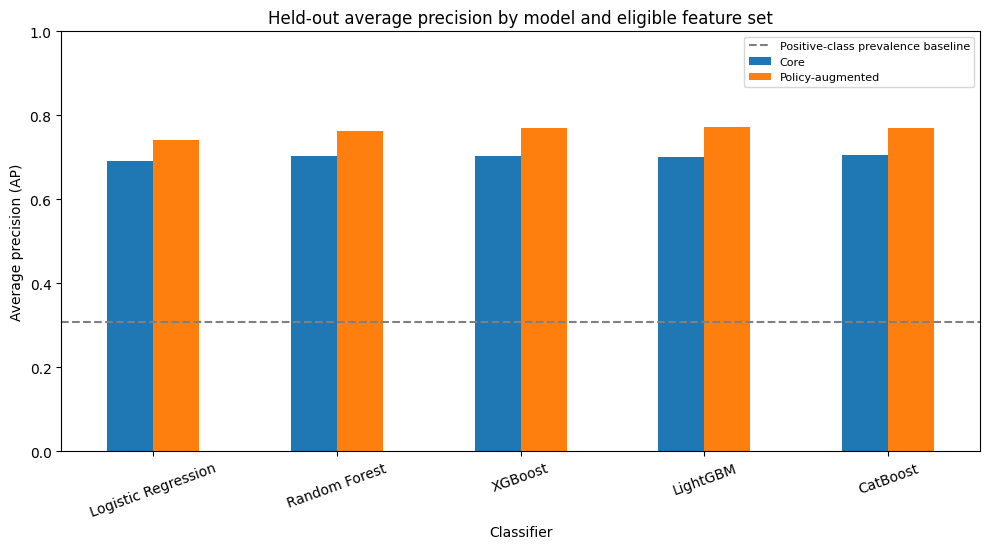

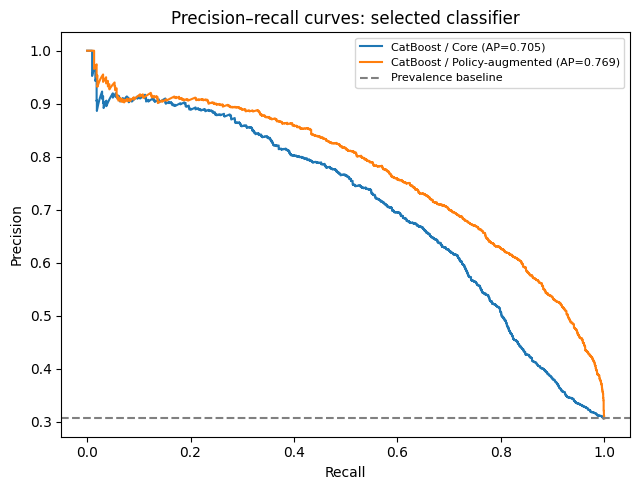

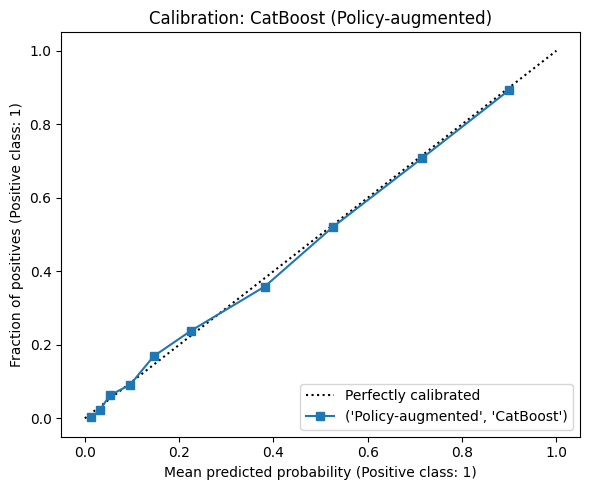

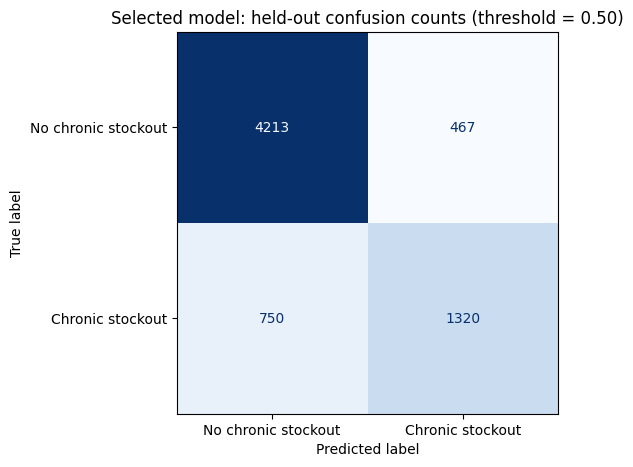

In [11]:
# Plot 1 — side-by-side average precision on the common held-out test partition
comparison = test_results.pivot(index='model', columns='feature_set', values='average_precision')
comparison = comparison.reindex(list(get_models().keys()))
ax = comparison.plot.bar(figsize=(10,5.6), rot=20)
ax.axhline(y_test.mean(), color='gray', linestyle='--', linewidth=1.5, label='Positive-class prevalence baseline')
ax.set_title('Held-out average precision by model and eligible feature set')
ax.set_xlabel('Classifier'); ax.set_ylabel('Average precision (AP)')
ax.set_ylim(0,1); ax.legend(loc='best', fontsize=8)
plt.tight_layout(); plt.savefig(FIG/'model_comparison_average_precision.png', dpi=200, bbox_inches='tight');plt.show()

# Plot 2 — precision-recall curves for selected model and its core/policy counterpart
plt.figure(figsize=(6.5,5))
for group in FEATURE_SETS:
    p = test_probas[(group, selected_key[1])]
    precision, recall, _ = precision_recall_curve(y_test, p)
    plt.plot(recall, precision, label=f'{selected_key[1]} / {group} (AP={average_precision_score(y_test,p):.3f})')
plt.axhline(y_test.mean(), color='gray', ls='--', label='Prevalence baseline')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–recall curves: selected classifier')
plt.legend(fontsize=8);plt.tight_layout();plt.savefig(FIG/'selected_precision_recall_curve.png', dpi=200,bbox_inches='tight');plt.show()

# Plot 3 — calibration on test records of validation-selected model
p_selected = test_probas[selected_key]
fig, ax = plt.subplots(figsize=(6.0,5.0))
CalibrationDisplay.from_predictions(y_test, p_selected, n_bins=10, strategy='quantile', ax=ax, name=str(selected_key))
ax.set_title(f'Calibration: {selected_key[1]} ({selected_key[0]})')
plt.tight_layout();plt.savefig(FIG/'selected_calibration.png', dpi=200,bbox_inches='tight');plt.show()

# Plot 4 — selected confusion matrix at fixed decision threshold 0.50
pred_selected = (p_selected >= 0.50).astype(int)
cm = confusion_matrix(y_test,pred_selected,labels=[0,1]);
fig, ax = plt.subplots(figsize=(5.5,4.8))
ConfusionMatrixDisplay(cm,display_labels=['No chronic stockout','Chronic stockout']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Selected model: held-out confusion counts (threshold = 0.50)')
plt.tight_layout();plt.savefig(FIG/'selected_confusion_matrix.png', dpi=200,bbox_inches='tight');plt.show()


## 8. Feature sensitivity: permutation importance on validation records (not causal effects)

,feature,mean_AP_decrease,std_AP_decrease
13,safety_stock,0.31070,0.00679
1,ignores_lead_time_variability,0.15354,0.00591
6,sigma_lead_time,0.11218,0.00313
12,target_service_level,0.04663,0.00266
4,demand_cv,0.04483,0.00207
3,sigma_daily_demand,0.02687,0.00033
14,reorder_point,0.02665,0.00376
7,lead_time_cv,0.01925,0.00181
2,mean_daily_demand,0.01554,0.00063
0,category,0.00300,0.00073


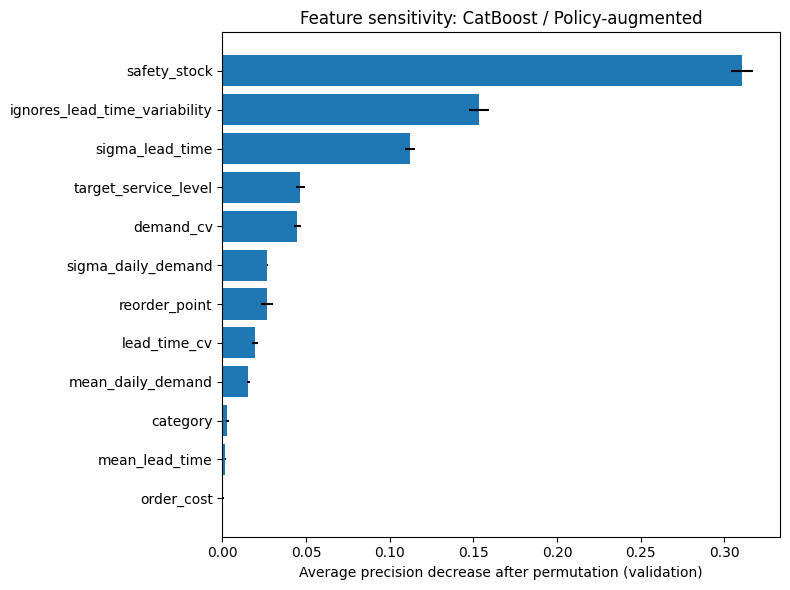

In [12]:
selected_features = FEATURE_SETS[selected_key[0]]
chosen_model = fitted[selected_key]
# Manual permutation importance is compatible with CatBoost and all sklearn versions.
# Every permutation is evaluated on the validation set, not the held-out test set.
X_sensitivity = df.iloc[val_idx][selected_features].copy()
base_ap = average_precision_score(y_val, predict_positive(chosen_model, X_sensitivity))
rng = np.random.default_rng(SEED)
perm_means, perm_stds = [], []
for col in selected_features:
    deltas = []
    for repeat in range(3):
        X_changed = X_sensitivity.copy()
        X_changed[col] = rng.permutation(X_changed[col].to_numpy())
        ap_changed = average_precision_score(y_val, predict_positive(chosen_model, X_changed))
        deltas.append(base_ap - ap_changed)
    perm_means.append(float(np.mean(deltas)))
    perm_stds.append(float(np.std(deltas)))
perm_table = pd.DataFrame({'feature': selected_features,
     'mean_AP_decrease': perm_means, 'std_AP_decrease': perm_stds})
perm_table = perm_table.sort_values('mean_AP_decrease', ascending=False)
perm_table.to_csv(TAB/'selected_permutation_importance.csv', index=False)
display(perm_table.round(5))
fig,ax=plt.subplots(figsize=(8,6))
plot_data=perm_table.head(12).iloc[::-1]
ax.barh(plot_data.feature,plot_data.mean_AP_decrease, xerr=plot_data.std_AP_decrease)
ax.set_xlabel('Average precision decrease after permutation (validation)')
ax.set_title(f'Feature sensitivity: {selected_key[1]} / {selected_key[0]}')
plt.tight_layout();plt.savefig(FIG/'selected_feature_sensitivity.png',dpi=200,bbox_inches='tight');plt.show()


## 9. Record execution versions, settings, source details and evidence files

In [13]:
from hashlib import sha256
setup = {
 'source_file': DATA_PATH.name, 'source_sha256': sha256(DATA_PATH.read_bytes()).hexdigest(),
 'rows': int(df.shape[0]), 'source_columns': int(df.shape[1]),
 'target': TARGET, 'target_rule': 'stockout_frequency >= 0.20',
 'seed': SEED, 'split': {'train': len(train_idx), 'validation': len(val_idx), 'test': len(test_idx)},
 'feature_sets': FEATURE_SETS,
 'models': list(get_models().keys()),
 'model_parameters': {name: model.get_params() for name,model in get_models().items()},
 'selection_metric': 'validation average_precision',
 'selected_model': {'feature_set': selected_key[0], 'model': selected_key[1]},
 'classification_threshold': 0.50,
 'versions': {'python':sys.version.split()[0], 'pandas':pd.__version__, 'numpy':np.__version__,
              'scikit-learn':sklearn.__version__, 'xgboost':xgboost.__version__,
              'lightgbm':lightgbm.__version__, 'catboost':catboost.__version__,
              'matplotlib':plt.matplotlib.__version__, 'platform':platform.platform()},
 'limitations': ['Simulated SKU-level summary data, not timestamped cycles',
                 'Held-out random classification does not validate forward forecasting',
                 'Predictive associations do not identify causal effects or savings',
                 'Fixed model hyperparameters; no cross-validated tuning in this initial run']
}
with open(OUT/'experiment_setup.json','w') as f:json.dump(setup,f,indent=2,default=str)
print('Outputs written to:', OUT.resolve())
print('TABLES:',[p.name for p in sorted(TAB.glob('*'))])
print('FIGURES:',[p.name for p in sorted(FIG.glob('*'))])
print('Python package versions:',setup['versions'])


Outputs written to: /content/outputs
TABLES: ['selected_permutation_importance.csv', 'test_metrics.csv', 'validation_metrics.csv']
FIGURES: ['model_comparison_average_precision.png', 'selected_calibration.png', 'selected_confusion_matrix.png', 'selected_feature_sensitivity.png', 'selected_precision_recall_curve.png']
Python package versions: {'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'matplotlib': '3.10.0', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39'}


## Notes for IEEE manuscript

- Report held-out test metrics explicitly as **results of classification of a supplied simulated label**, not future-event forecast accuracy.
- Report model selection as based on **validation average precision**. All displayed test values use a fixed 0.50 threshold. **AP** is not identical to trapezoidal PR-AUC; name the measure accurately.
- The core and policy-augmented groups share the same train/validation/test records; no target-derived variables are predictors.
- The feature-sensitivity plot uses validation-set **permutation importance**. It does not measure causal impact or demonstrate that changing safety stock will save money.
- Training uses fixed hyperparameters (clearly documented); **do not claim cross-validated tuning** was performed. Optional tuning can be added later within training data.
- Reproduce results by using the original CSV and running cells from top to bottom. Upload outputs into GitHub after the manuscript is complete.


In [14]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/AMLBT_Phase2_Results",
    "zip",
    "/content/outputs"
)

files.download("/content/AMLBT_Phase2_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Review capacity (%),Records reviewed,Chronic cases found,Precision (%),Cases captured (%),Lift over random,Shortage cost share (%),Total cost share (%)
0,5,338,306,90.53,14.78,2.95,9.04,7.75
1,10,675,603,89.33,29.13,2.91,27.88,23.04
2,20,1350,1081,80.07,52.22,2.61,52.76,43.85


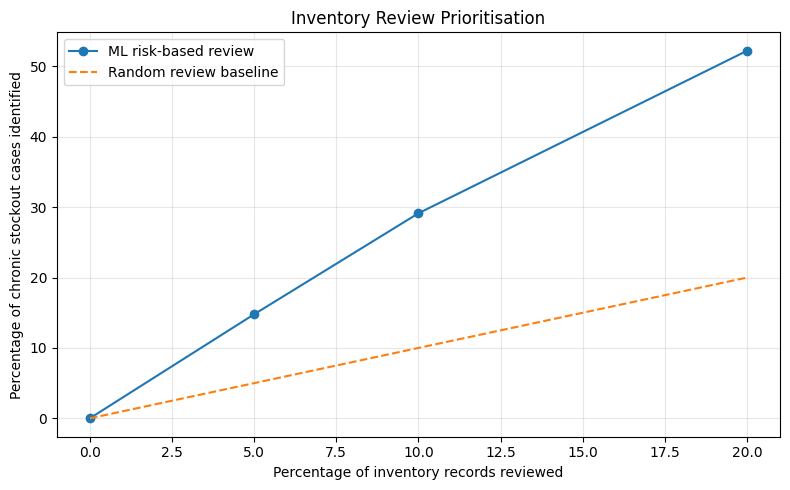

In [15]:

# Phase 3: Business Application — Inventory Review Prioritisation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the model selected on validation data
business_df = df.iloc[test_idx].copy().reset_index(drop=True)
business_df["risk_score"] = test_probas[selected_key]

# Rank inventory records from highest to lowest risk
business_df = business_df.sort_values(
    "risk_score", ascending=False, kind="mergesort"
).reset_index(drop=True)

total_positives = business_df["stockout_occurred"].sum()
baseline = total_positives / len(business_df)

results = []

for capacity in [5, 10, 20]:
    n = int(np.ceil(len(business_df) * capacity / 100))
    reviewed = business_df.head(n)

    positives = int(reviewed["stockout_occurred"].sum())

    results.append({
        "Review capacity (%)": capacity,
        "Records reviewed": n,
        "Chronic cases found": positives,
        "Precision (%)": round(100 * positives / n, 2),
        "Cases captured (%)": round(
            100 * positives / total_positives, 2
        ),
        "Lift over random": round(
            (positives / n) / baseline, 2
        ),
        "Shortage cost share (%)": round(
            100 * reviewed["shortage_cost"].sum()
            / business_df["shortage_cost"].sum(), 2
        ),
        "Total cost share (%)": round(
            100 * reviewed["total_cost"].sum()
            / business_df["total_cost"].sum(), 2
        )
    })

business_results = pd.DataFrame(results)
display(business_results)

# Save the results
business_results.to_csv(
    "outputs/tables/business_prioritisation.csv", index=False
)

# Business prioritisation graph
plt.figure(figsize=(8, 5))

plt.plot(
    [0] + business_results["Review capacity (%)"].tolist(),
    [0] + business_results["Cases captured (%)"].tolist(),
    marker="o", label="ML risk-based review"
)

plt.plot(
    [0, 20], [0, 20],
    "--", label="Random review baseline"
)

plt.xlabel("Percentage of inventory records reviewed")
plt.ylabel("Percentage of chronic stockout cases identified")
plt.title("Inventory Review Prioritisation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/business_prioritisation.png",
    dpi=200
)
plt.show()


In [16]:

# Business benchmark: ML versus conventional inventory control

import numpy as np
import pandas as pd
from pathlib import Path

# Use the CatBoost model selected during validation
assert selected_key in fitted
model = fitted[selected_key]
features = FEATURE_SETS[selected_key[0]]

def compare_methods(indices, split_name):
    data = df.iloc[indices].copy().reset_index(drop=True)

    # ML model risk scores
    ml_scores = model.predict_proba(data[features])[:, 1]

    # Conventional safety-stock coverage rule
    # Assumes independent daily demand and lead-time variability
    uncertainty = np.sqrt(
        data["sigma_daily_demand"]**2
        * data["mean_lead_time"]
        +
        data["mean_daily_demand"]**2
        * data["sigma_lead_time"]**2
    )

    coverage = data["safety_stock"] / uncertainty.clip(lower=1e-9)

    # Lower coverage = greater risk
    conventional_scores = -coverage

    results = []
    positive_total = int(data["stockout_occurred"].sum())

    for name, scores in {
        "CatBoost ML": ml_scores,
        "Safety-stock rule": conventional_scores
    }.items():

        order = np.argsort(-np.asarray(scores), kind="stable")

        for capacity in [5, 10, 20]:
            n = int(np.ceil(len(data) * capacity / 100))
            reviewed = data.iloc[order[:n]]

            found = int(reviewed["stockout_occurred"].sum())

            results.append({
                "Split": split_name,
                "Method": name,
                "Capacity (%)": capacity,
                "Reviewed": n,
                "Chronic cases found": found,
                "Precision (%)": round(100 * found / n, 2),
                "Cases captured (%)": round(
                    100 * found / positive_total, 2
                ),
                "Shortage cost share (%)": round(
                    100 * reviewed["shortage_cost"].sum()
                    / data["shortage_cost"].sum(), 2
                )
            })

    return pd.DataFrame(results)

# Report both partitions
validation_comparison = compare_methods(val_idx, "Validation")
test_comparison = compare_methods(test_idx, "Test")

business_comparison = pd.concat(
    [validation_comparison, test_comparison],
    ignore_index=True
)

display(business_comparison)

Path("outputs/tables").mkdir(parents=True, exist_ok=True)

business_comparison.to_csv(
    "outputs/tables/business_method_comparison.csv",
    index=False
)


,Split,Method,Capacity (%),Reviewed,Chronic cases found,Precision (%),Cases captured (%),Shortage cost share (%)
0,Validation,CatBoost ML,5,338,314,92.90,15.17,9.95
1,Validation,CatBoost ML,10,675,615,91.11,29.71,23.31
2,Validation,CatBoost ML,20,1350,1112,82.37,53.72,48.47
3,Validation,Safety-stock rule,5,338,321,94.97,15.51,12.51
4,Validation,Safety-stock rule,10,675,615,91.11,29.71,24.41
5,Validation,Safety-stock rule,20,1350,1121,83.04,54.15,48.72
6,Test,CatBoost ML,5,338,306,90.53,14.78,9.04
7,Test,CatBoost ML,10,675,603,89.33,29.13,27.88
8,Test,CatBoost ML,20,1350,1081,80.07,52.22,52.76
9,Test,Safety-stock rule,5,338,312,92.31,15.07,16.38


In [17]:

# Phase 4: Financial decision and break-even analysis

import numpy as np
import pandas as pd
from pathlib import Path

# Use the same held-out test records and selected model
data = df.iloc[test_idx].copy().reset_index(drop=True)

model = fitted[selected_key]
features = FEATURE_SETS[selected_key[0]]

data["ML_score"] = model.predict_proba(
    data[features]
)[:, 1]

# Conventional safety-stock coverage score
uncertainty = np.sqrt(
    data["sigma_daily_demand"]**2 * data["mean_lead_time"]
    + data["mean_daily_demand"]**2 * data["sigma_lead_time"]**2
)

data["Rule_score"] = (
    -data["safety_stock"] / uncertainty.clip(lower=1e-9)
)

# Illustrative management capacity: top 10%
n = int(np.ceil(len(data) * 0.10))

summary = []
selections = {}

for name, column in [
    ("CatBoost ML", "ML_score"),
    ("Conventional rule", "Rule_score")
]:
    selected = data.sort_values(
        column, ascending=False, kind="mergesort"
    ).head(n)

    selections[name] = selected

    summary.append({
        "Method": name,
        "Records reviewed": n,
        "Chronic cases": int(
            selected["stockout_occurred"].sum()
        ),
        "Simulated shortage-cost exposure": float(
            selected["shortage_cost"].sum()
        )
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

# Financial sensitivity: assumed fraction of exposure avoided
scenarios = []

for _, item in summary_df.iterrows():
    exposure = item["Simulated shortage-cost exposure"]

    for reduction in [0.02, 0.05, 0.10]:
        hypothetical_benefit = exposure * reduction

        scenarios.append({
            "Method": item["Method"],
            "Assumed shortage-cost reduction (%)":
                reduction * 100,
            "Hypothetical avoided cost":
                round(hypothetical_benefit, 2),
            "Maximum total cost per review for break-even":
                round(hypothetical_benefit / n, 2)
        })

financial_results = pd.DataFrame(scenarios)

print("FINANCIAL SENSITIVITY ANALYSIS")
display(financial_results)

# How effective must ML interventions be to match the rule?
ml_exposure = summary_df.loc[
    summary_df["Method"] == "CatBoost ML",
    "Simulated shortage-cost exposure"
].iloc[0]

rule_exposure = summary_df.loc[
    summary_df["Method"] == "Conventional rule",
    "Simulated shortage-cost exposure"
].iloc[0]

assumed_rule_reduction = 0.05

required_ml_reduction = (
    assumed_rule_reduction * rule_exposure / ml_exposure
)

print(
    "If the conventional rule avoids 5% of its selected "
    "shortage-cost exposure, ML needs an avoidance rate of "
    f"{required_ml_reduction * 100:.2f}% to match it, "
    "before additional ML system costs."
)

# Save outputs
Path("outputs/tables").mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    "outputs/tables/financial_exposure_comparison.csv",
    index=False
)

financial_results.to_csv(
    "outputs/tables/financial_sensitivity.csv",
    index=False
)


,Method,Records reviewed,Chronic cases,Simulated shortage-cost exposure
0,CatBoost ML,675,603,2394444.03
1,Conventional rule,675,608,2785190.39


FINANCIAL SENSITIVITY ANALYSIS


,Method,Assumed shortage-cost reduction (%),Hypothetical avoided cost,Maximum total cost per review for break-even
0,CatBoost ML,2.0,47888.88,70.95
1,CatBoost ML,5.0,119722.20,177.37
2,CatBoost ML,10.0,239444.40,354.73
3,Conventional rule,2.0,55703.81,82.52
4,Conventional rule,5.0,139259.52,206.31
5,Conventional rule,10.0,278519.04,412.62


If the conventional rule avoids 5% of its selected shortage-cost exposure, ML needs an avoidance rate of 5.82% to match it, before additional ML system costs.
